# Hello world: two point sources (Tsang superresolution)

Two incoherent point sources separated along the $x$-axis and kept in focus
($z = 0$). They sit symmetrically at $\mp d/2$, so $d$ is the full separation. For
each $d$ we compute the Fisher information for $d$ with two measurements:

- **QFI** — the quantum bound (optimal measurement).
- **FI-MS** — a Hermite-Gaussian mode-sorting measurement (SPADE).

Tsang's result [PRX 6, 031033 (2016)]: the QFI stays **flat** as the separation
shrinks — it does *not* collapse to zero (no Rayleigh's curse) — and mode sorting
**saturates** it, so **FI-MS = QFI** at every separation.

Run `python simulate_bounds.py` first to generate `qfi.npy`, `fi_ms.npy`,
`spacing.npy`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from rayfish.visualize_helpers import latexify

latexify()
FORMAT = "pdf"

In [2]:
%matplotlib inline

## Load data

The estimated parameter is the full separation $d = s_2 - s_1$, with the sources at
$\mp d/2 = \mp\,$`spacing`. We report it in normalized transverse units
$\sqrt{k/z_R}\,d$, so the axis relates back to the wave vector $k$ and the Rayleigh
length $z_R$. With $k = 2$, $z_R = 1$ (as in `simulate_bounds.py`) this is the
$\sigma = 1$ PSF-width convention.

In [3]:
ROOT = Path.cwd()
qfi = np.load(ROOT / "qfi.npy")  # (M,) QFI for the separation d
fi_ms = np.load(ROOT / "fi_ms.npy")  # (M,) mode-sorting FI, summed over channels
spacing = np.load(ROOT / "spacing.npy")  # (M,) each source sits at +/- spacing

# Optical scale, matching simulate_bounds.py (sigma = 1 convention).
WAVE_VECTOR = 2.0
RAYLEIGH_LENGTH = 1.0

# Full separation d = s2 - s1 = 2 * spacing, in normalized transverse units.
separation = 2.0 * spacing
sep_normalized = np.sqrt(WAVE_VECTOR / RAYLEIGH_LENGTH) * separation

## Mode sorting saturates the flat QFI

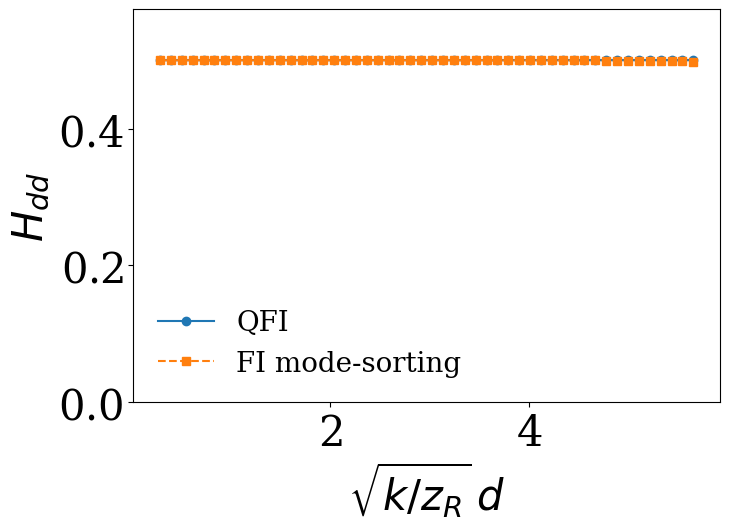

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(sep_normalized, qfi, "o-", label="QFI", color="C0")
ax.plot(sep_normalized, fi_ms, "s--", label="FI mode-sorting", color="C1")

ax.set_xlabel(r"$\sqrt{k/z_R}\,d$")
ax.set_ylabel(r"$H_{dd}$")
ax.set_ylim(0.0, 1.15 * max(qfi.max(), fi_ms.max()))
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(f"tsang_two_source.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

### What to read off the plot

- The **QFI is flat** — the information about the separation does not vanish as the
  sources merge. This is the headline Tsang result: no Rayleigh's curse.
- The **mode-sorting FI lies on top of the QFI** — SPADE is the optimal measurement
  for the separation. Any small deviation at the largest separations is finite-mode
  truncation; raise `MODE_DEGREE` in `simulate_bounds.py` to close it.